In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_auc_score, brier_score_loss)
import joblib
import shap
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ["Pregnancies","Glucose","BloodPressure","SkinThickness",
        "Insulin","BMI","DiabetesPedigreeFunction","Age","Outcome"]
df = pd.read_csv(url, names=cols)

# Treat impossible zeros as missing values
df[["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]] = \
    df[["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]].replace(0, np.nan)

X, y = df.drop(columns="Outcome"), df["Outcome"]
print(f"Dataset shape: {df.shape}")
print("Missing values handled (zeros mapped to NaN).")

Dataset shape: (768, 9)
Missing values handled (zeros mapped to NaN).


In [2]:
# 60/20/20 Train / Val / Test Split
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, stratify=y_trainval, random_state=42)

print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

Train: (460, 8) | Val: (154, 8) | Test: (154, 8)


In [3]:
# Define models
baseline = DummyClassifier(strategy="most_frequent")
logreg = Pipeline([("imputer", SimpleImputer(strategy="median")),
                   ("scaler", StandardScaler()),
                   ("clf", LogisticRegression(max_iter=1000, random_state=42))])
rf = Pipeline([("imputer", SimpleImputer(strategy="median")),
               ("clf", RandomForestClassifier(n_estimators=300, random_state=42))])

# Train on training set only
baseline.fit(X_train, y_train)
logreg.fit(X_train, y_train)
rf.fit(X_train, y_train)

print("Models trained on training data.")

Models trained on training data.


In [4]:
# Threshold sweep on validation set ONLY
val_probs = logreg.predict_proba(X_val)[:, 1]

print("=== Threshold sweep on VALIDATION (Logistic Regression) ===")
print("thr  | Rec   | Prec  | F1    | FN | FP")
for thr in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    preds = (val_probs >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, preds).ravel()
    print(f"{thr:.2f} | {recall_score(y_val, preds):.3f} | "
          f"{precision_score(y_val, preds, zero_division=0):.3f} | "
          f"{f1_score(y_val, preds):.3f} | {fn:2d} | {fp:2d}")

# We select 0.40 as a deliberate precision-recall trade-off.
# Compared with 0.25, it improves validation precision and reduces
# false positives, but also lowers recall and increases false negatives.
# This is a prototype choice, not a clinically validated threshold.
CHOSEN_THR = 0.40
print(f"\n→ SELECTED THRESHOLD: {CHOSEN_THR}")

# Final test evaluation (run ONCE)
print("\n=== FINAL TEST EVALUATION (LogReg @ thr=0.40) ===")
test_probs = logreg.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= CHOSEN_THR).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, test_preds).ravel()

print(f"Accuracy : {accuracy_score(y_test, test_preds):.3f}")
print(f"Precision: {precision_score(y_test, test_preds, zero_division=0):.3f}")
print(f"Recall   : {recall_score(y_test, test_preds):.3f}")
print(f"F1 Score : {f1_score(y_test, test_preds):.3f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, test_probs):.3f}")
print(f"Brier    : {brier_score_loss(y_test, test_probs):.3f}")
print(f"Confusion: TN={tn} FP={fp} FN={fn} TP={tp}")

# Age-Group Performance (Exploratory)
print("\n=== Age-Group Performance (Test Set) ===")
test_ages = X_test['Age'].values
for lo, hi in [(21, 30), (30, 40), (40, 50), (50, 100)]:
    mask = (test_ages >= lo) & (test_ages < hi)
    if mask.sum() > 0:
        rec = recall_score(y_test[mask], test_preds[mask], zero_division=0)
        print(f"Age [{lo}, {hi}): n={mask.sum()}, Recall={rec:.3f}")

=== Threshold sweep on VALIDATION (Logistic Regression) ===
thr  | Rec   | Prec  | F1    | FN | FP
0.20 | 0.889 | 0.533 | 0.667 |  6 | 42
0.25 | 0.815 | 0.595 | 0.688 | 10 | 30
0.30 | 0.741 | 0.588 | 0.656 | 14 | 28
0.35 | 0.667 | 0.643 | 0.655 | 18 | 20
0.40 | 0.667 | 0.679 | 0.673 | 18 | 17
0.45 | 0.630 | 0.723 | 0.673 | 20 | 13
0.50 | 0.593 | 0.727 | 0.653 | 22 | 12

→ SELECTED THRESHOLD: 0.4

=== FINAL TEST EVALUATION (LogReg @ thr=0.40) ===
Accuracy : 0.721
Precision: 0.604
Recall   : 0.593
F1 Score : 0.598
ROC-AUC  : 0.817
Brier    : 0.175
Confusion: TN=79 FP=21 FN=22 TP=32

=== Age-Group Performance (Test Set) ===
Age [21, 30): n=85, Recall=0.438
Age [30, 40): n=30, Recall=0.600
Age [40, 50): n=24, Recall=0.833
Age [50, 100): n=15, Recall=0.500


In [5]:
# Retrain on the full Train + Val set (exclude Test)
final_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=42))
]).fit(X_trainval, y_trainval)

joblib.dump(final_model, "healthsignal_final.pkl")
print("Saved healthsignal_final.pkl")

Saved healthsignal_final.pkl


In [6]:
# Extract the SAME preprocessing steps used by the final model
imputer = final_model.named_steps["imputer"]
scaler = final_model.named_steps["scaler"]

X_trainval_imp = imputer.transform(X_trainval)
X_trainval_scaled = scaler.transform(X_trainval_imp)
background = X_trainval_scaled[:100]

joblib.dump(background, "shap_background.pkl")
print("Saved shap_background.pkl with shape:", background.shape)

from google.colab import files
files.download("healthsignal_final.pkl")
files.download("shap_background.pkl")

Saved shap_background.pkl with shape: (100, 8)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

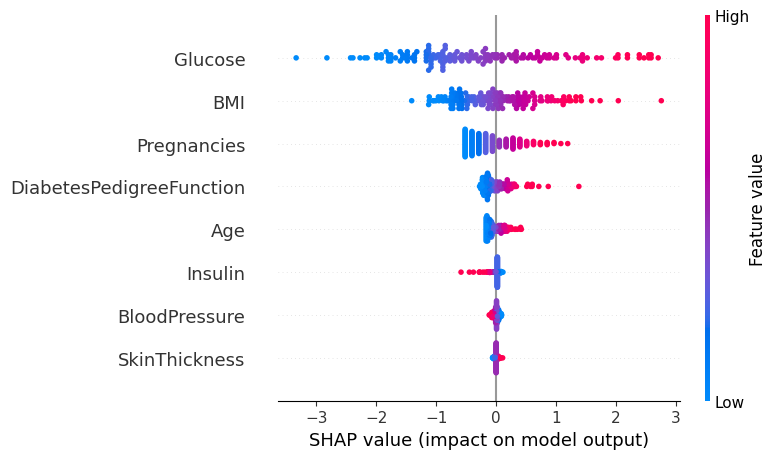

In [7]:
clf = final_model.named_steps["clf"]
X_test_imp = imputer.transform(X_test)
X_test_scaled = scaler.transform(X_test_imp)

explainer = shap.LinearExplainer(clf, background)
shap_values = explainer.shap_values(X_test_scaled)

shap.summary_plot(shap_values, X_test_scaled, feature_names=X.columns, show=True)